## Generate Images with FLUX.1-Kontext-pro

In this notebook, we use the **FLUX.1-Kontext-pro** model from Black Forest Labs, deployed as a serverless endpoint on Azure AI Foundry, to generate images from text prompts.

FLUX.1 Kontext is a state-of-the-art image generation model known for:
- High-quality, detailed image output
- Excellent text rendering inside images
- Fast generation (~0.9s per 1024x1024 image)

We'll call the model's OpenAI-compatible `/images/generations` endpoint directly using Python.

**Prerequisite:** Deploy `FLUX.1-Kontext-pro` from the Foundry portal (Models + endpoints -> Foundry Models -> search "FLUX.1-Kontext-pro" -> Deploy). After deployment, copy the **Target URI** from the deployment details page into your `.env` file.

### Step 1: Install Packages

We need `requests` to call the REST API, `azure-identity` for authentication, and `python-dotenv` to load our settings.

In [11]:
# Install everything we need in a single command
# - requests: makes HTTP calls to the image generation endpoint
# - azure-identity: handles Azure authentication (DefaultAzureCredential)
# - python-dotenv: loads settings from a .env file
%pip install requests azure-identity python-dotenv

Note: you may need to restart the kernel to use updated packages.


### Step 2: Load Settings

Our settings are stored in a `.env` file:
- `FOUNDRY_RESOURCE_ENDPOINT` — the **Target URI** from the FLUX deployment page (e.g., `https://your-resource.cognitiveservices.azure.com`). This is NOT the project endpoint.
- `IMAGE_MODEL_DEPLOYMENT_NAME` — the FLUX deployment name (e.g., `FLUX.1-Kontext-pro`)

In [13]:
import os
import requests
from dotenv import load_dotenv

load_dotenv()

FOUNDRY_ENDPOINT = os.getenv("FOUNDRY_ENDPOINT")
IMAGE_MODEL_DEPLOYMENT_NAME = os.getenv("IMAGE_MODEL_DEPLOYMENT_NAME")

generation_url = (
    f"{FOUNDRY_ENDPOINT}/openai/v1/images/generations"
    "?api-version=preview"
)

first_prompt = (
    "A vintage travel poster for a magical floating city above the clouds, "
    "with hot air balloons, golden sunlight, and the text "
    "'Visit Sky Harbor' at the bottom in bold retro lettering."
)

request_body = {
    "model": IMAGE_MODEL_DEPLOYMENT_NAME,
    "prompt": first_prompt,
    "n": 1,
    "size": "1024x1024",
}

headers = {
    "api-key": os.getenv("AZURE_API_KEY"),
    "Content-Type": "application/json",
}

print("Generating image...")

response = requests.post(
    generation_url,
    headers=headers,
    json=request_body,
    timeout=300,
)

print("HTTP status:", response.status_code)

if not response.ok:
    print("API error:")
    print(response.text)

response.raise_for_status()

result = response.json()

print("Image generated successfully!")

print(result)

Generating image...
HTTP status: 200
Image generated successfully!
{'created': 1791280513, 'data': [{'url': None, 'b64_json': '...', 'content_filter_results': None, 'revised_prompt': None, 'prompt_filter_results': None}]}


In [3]:
# os lets us read environment variables from the system
import os

# base64 lets us decode the image data returned by the API
import base64

# requests lets us make HTTP calls to the FLUX endpoint
import requests

# load_dotenv reads your .env file and sets each line as an environment variable
from dotenv import load_dotenv

# DefaultAzureCredential automatically picks the best way to authenticate with Azure
from azure.identity import DefaultAzureCredential

# IPython.display lets us show images directly in a Jupyter notebook
from IPython.display import Image, display

# Load the .env file so os.getenv() can find our settings
load_dotenv()

# The Target URI from the FLUX deployment page (e.g. https://your-resource.cognitiveservices.azure.com)
# Important: this is NOT the project endpoint -- copy it from the deployment details page
my_endpoint = os.getenv("FOUNDRY_RESOURCE_ENDPOINT")

# The name of the FLUX.1-Kontext-pro deployment in your Foundry project
my_image_model = os.getenv("IMAGE_MODEL_DEPLOYMENT_NAME")

if not my_endpoint:
    raise ValueError("FOUNDRY_RESOURCE_ENDPOINT is not set in your .env file. Copy the Target URI from the FLUX deployment page.")
if not my_image_model:
    raise ValueError("IMAGE_MODEL_DEPLOYMENT_NAME is not set in your .env file.")

print(f"Endpoint: {my_endpoint}")
print(f"Image model: {my_image_model}")

Endpoint: https://foundrydemodemo369.services.ai.azure.com/api/projects/foundry-demo
Image model: FLUX.1-Kontext-pro


### Step 3: Authenticate with Azure

Since API key authentication is disabled on this deployment, we use `DefaultAzureCredential` to get a **bearer token**. This automatically detects how you are logged in (Azure CLI, VS Code, managed identity, etc.).

In [14]:
# Create a credential object that automatically detects how you are logged in
credential = DefaultAzureCredential()


def get_auth_headers():
    """Get fresh authorization headers. Call this before each API request
    to avoid token expiry errors (tokens last ~1 hour)."""
    token = credential.get_token("https://cognitiveservices.azure.com/.default")
    return {
        "Authorization": f"Bearer {token.token}",
        "Content-Type": "application/json",
    }


print("Authentication successful — credential ready.")

Authentication successful — credential ready.


### Step 4: Build the API URL and Headers

FLUX.1-Kontext-pro is exposed through an OpenAI-compatible REST endpoint.  
The URL follows this pattern:

```
{target_uri}/openai/deployments/{deployment}/images/generations?api-version=2025-04-01-preview
```

We authenticate using the **bearer token** from the previous step.

In [15]:
# The API version required for image generation with FLUX models
api_version = "2025-04-01-preview"

# Build the full URL for the image generation endpoint
generation_url = (
    f"{my_endpoint}/openai/deployments/{my_image_model}"
    f"/images/generations?api-version={api_version}"
)

print(f"API URL ready: .../{my_image_model}/images/generations")

API URL ready: .../FLUX.1-Kontext-pro/images/generations


In [17]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Explicitly load Image-Generation/.env
env_path = Path.cwd() / ".env"

print("Current directory:", Path.cwd())
print("Loading .env:", env_path)
print("Exists:", env_path.exists())

load_dotenv(env_path, override=True)

FOUNDRY_ENDPOINT = os.getenv("FOUNDRY_ENDPOINT")
IMAGE_MODEL_DEPLOYMENT_NAME = os.getenv("IMAGE_MODEL_DEPLOYMENT_NAME")
AZURE_API_KEY = os.getenv("AZURE_API_KEY")

print()
print("Endpoint:", FOUNDRY_ENDPOINT)
print("Model:", IMAGE_MODEL_DEPLOYMENT_NAME)
print("API key loaded:", bool(AZURE_API_KEY))
print("API key length:", len(AZURE_API_KEY) if AZURE_API_KEY else 0)

Current directory: c:\Users\Ashok\OneDrive\Documents\Microsoft-Foundry-Source-Code\Microsoft-Foundry-Source-Code\Foundry-Agent-Service\Image-Generation
Loading .env: c:\Users\Ashok\OneDrive\Documents\Microsoft-Foundry-Source-Code\Microsoft-Foundry-Source-Code\Foundry-Agent-Service\Image-Generation\.env
Exists: True

Endpoint: https://foundrydemodemo369.services.ai.azure.com
Model: FLUX.1-Kontext-pro
API key loaded: True
API key length: 84


### Step 5: Generate the First Image

We send a text prompt to the FLUX model and get back a base64-encoded PNG image.  
Let's create a vintage travel poster for a fictional floating city.

In [19]:
import requests

# Correct FLUX Image API endpoint
generation_url = (
    f"{FOUNDRY_ENDPOINT}"
    "/openai/v1/images/generations"
    "?api-version=preview"
)

# Image prompt
first_prompt = (
    "A vintage travel poster for a magical floating city above the clouds, "
    "with hot air balloons, golden sunlight, and the text "
    "'Visit Sky Harbor' at the bottom in bold retro lettering."
)

# Request body
request_body = {
    "model": IMAGE_MODEL_DEPLOYMENT_NAME,
    "prompt": first_prompt,
    "n": 1,
    "size": "1024x1024",
}

# API-key authentication
headers = {
    "api-key": AZURE_API_KEY,
    "Content-Type": "application/json",
}

print("Generating image...")
print("URL:", generation_url)
print("Model:", IMAGE_MODEL_DEPLOYMENT_NAME)

response = requests.post(
    generation_url,
    headers=headers,
    json=request_body,
    timeout=300,
)

print("HTTP status:", response.status_code)

if not response.ok:
    print("API error:")
    print(response.text)

response.raise_for_status()

result = response.json()

print("Image generated successfully!")
print(result)

Generating image...
URL: https://foundrydemodemo369.services.ai.azure.com/openai/v1/images/generations?api-version=preview
Model: FLUX.1-Kontext-pro
HTTP status: 200
Image generated successfully!
{'created': 1791280725, 'data': [{'url': None, 'b64_json': '...', 'content_filter_results': None, 'revised_prompt': None, 'prompt_filter_results': None}]}


### Step 6: Save and Display the Image

The API returns the image as a base64-encoded string inside the `data` array.  
We decode it and save it as a PNG file, then display it in the notebook.

Image saved: c:\Users\Ashok\OneDrive\Documents\Microsoft-Foundry-Source-Code\Microsoft-Foundry-Source-Code\Foundry-Agent-Service\Image-Generation\sky_harbor_poster.png


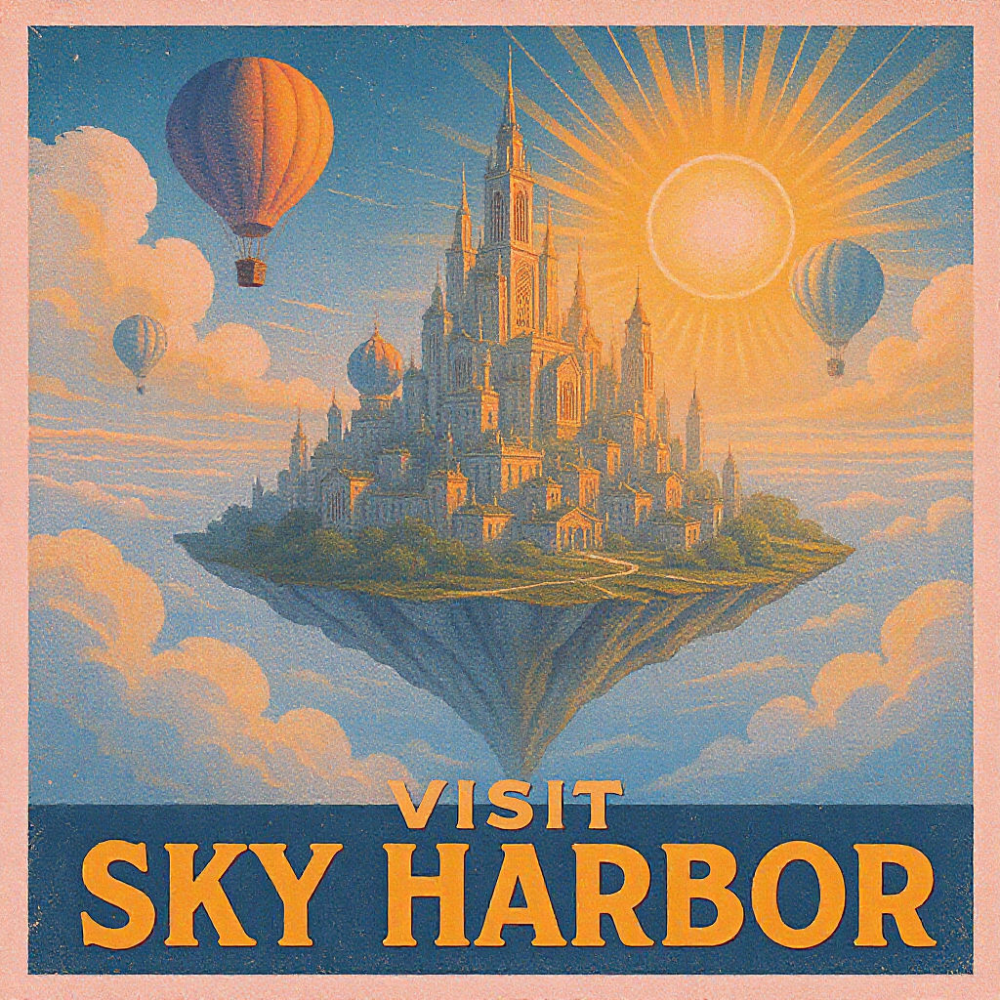

In [21]:
# Extract the base64-encoded image from the response
# The response format is: {"data": [{"b64_json": "..."}]}
b64_image_data = result["data"][0]["b64_json"]

# Decode the base64 string into raw image bytes
image_bytes = base64.b64decode(b64_image_data)

# Save the image to a local file
first_filename = "sky_harbor_poster.png"
with open(first_filename, "wb") as f:
    f.write(image_bytes)

print(f"Image saved: {os.path.abspath(first_filename)}")

# Display the image inline in the notebook
display(Image(filename=first_filename))

In [24]:
print("Endpoint:", FOUNDRY_ENDPOINT)
print("Deployment:", IMAGE_MODEL_DEPLOYMENT_NAME)
print("API key loaded:", bool(AZURE_API_KEY))
print("API key length:", len(AZURE_API_KEY) if AZURE_API_KEY else 0)

Endpoint: https://foundrydemodemo369.services.ai.azure.com
Deployment: FLUX.1-Kontext-pro
API key loaded: True
API key length: 84


### Step 7: Generate a Second Image (Different Prompt)

Let's try a completely different scene to see the model's range.  
This time we'll ask for a poster of a glowing underwater city.

In [23]:
import base64
import os
import requests

# -----------------------------------------
# 1. Second image prompt
# -----------------------------------------

second_prompt = (
    "A vintage travel poster for a glowing underwater city with coral towers, "
    "bioluminescent fish, a glass dome, and the text "
    "'Explore Coral Deep' at the bottom in art deco lettering."
)

# -----------------------------------------
# 2. Request body
# -----------------------------------------

second_body = {
    "model": IMAGE_MODEL_DEPLOYMENT_NAME,
    "prompt": second_prompt,
    "n": 1,
    "size": "1024x1024",
}

# -----------------------------------------
# 3. Authentication
# -----------------------------------------

headers = {
    "api-key": AZURE_API_KEY,
    "Content-Type": "application/json",
}

# -----------------------------------------
# 4. Generate image
# -----------------------------------------

print("Generating second image...")

second_response = requests.post(
    generation_url,
    headers=headers,
    json=second_body,
    timeout=300,
)

# -----------------------------------------
# 5. Debug response
# -----------------------------------------

print("HTTP status:", second_response.status_code)

if not second_response.ok:
    print("API error:")
    print(second_response.text)

second_response.raise_for_status()

# -----------------------------------------
# 6. Parse response
# -----------------------------------------

second_result = second_response.json()

print("Image generated successfully!")

print(second_result)

Generating second image...
HTTP status: 200
Image generated successfully!
{'created': 1791280895, 'data': [{'url': None, 'b64_json': '...', 'content_filter_results': None, 'revised_prompt': None, 'prompt_filter_results': None}]}


### Step 8: Try a Landscape Format

FLUX.1-Kontext-pro supports different aspect ratios.  
Let's generate a wide landscape image using `1792x1024` resolution.

In [26]:
import os
import requests

# -----------------------------------------
# 1. Landscape prompt
# -----------------------------------------

landscape_prompt = (
    "A breathtaking panoramic view of a futuristic city at sunset, "
    "with flying cars, neon-lit skyscrapers reflecting in a calm river, "
    "and cherry blossom trees lining the waterfront. Cinematic lighting."
)

# -----------------------------------------
# 2. Request body
# -----------------------------------------

landscape_body = {
    "model": IMAGE_MODEL_DEPLOYMENT_NAME,
    "prompt": landscape_prompt,
    "n": 1,
    "size": "1024x1024",
}

# -----------------------------------------
# 3. Authentication
# -----------------------------------------

headers = {
    "api-key": AZURE_API_KEY,
    "Content-Type": "application/json",
}

# -----------------------------------------
# 4. Generate image
# -----------------------------------------

print("Generating landscape image...")

landscape_response = requests.post(
    generation_url,
    headers=headers,
    json=landscape_body,
    timeout=300,
)

# -----------------------------------------
# 5. Check response
# -----------------------------------------

print("HTTP status:", landscape_response.status_code)

if not landscape_response.ok:
    print("API error:")
    print(landscape_response.text)

landscape_response.raise_for_status()

# -----------------------------------------
# 6. Parse JSON
# -----------------------------------------

landscape_result = landscape_response.json()

print("Landscape image generated successfully!")

print(landscape_result)

Generating landscape image...
HTTP status: 200
Landscape image generated successfully!
{'created': 1791280987, 'data': [{'url': None, 'b64_json': '...', 'content_filter_results': None, 'revised_prompt': None, 'prompt_filter_results': None}]}
